# Proyecto AFORE, 01: análisis de los rendimientos

La limpieza y la exploración detallada están en el notebook 00. Aquí uso `src/limpieza.py` y me concentro en cuatro preguntas:

1. Qué AFORE rinde más hoy en cada plazo.
2. Si la que gana a 12 meses es la misma que gana a 5 años.
3. Quién aguantó mejor la caída de 2022.
4. Cómo queda cada AFORE entre rendimiento y estabilidad.

Igual que antes, los rendimientos son ventanas móviles y los meses consecutivos no son independientes.

In [1]:
import sys, os
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from limpieza import cargar_y_limpiar, AFORES, PLAZOS

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
os.makedirs("../images/01", exist_ok=True)

df, gen, sistema = cargar_y_limpiar("../data/10_rendimientos_precio_bolsa.csv")
print("filas:", len(df), "| periodo:", df.fecha.min().date(), "a", df.fecha.max().date())

GEN = "90-94"   # cambia esto por tu generación (nacido en 1985 sería "85-89")
print("generaciones:", sorted(gen["fondo"].unique()))

filas: 38179 | periodo: 2019-12-01 a 2025-12-01
generaciones: ['55-59', '60-64', '65-69', '70-74', '75-79', '80-84', '85-89', '90-94', '95-99']


## 1. Qué AFORE rinde más hoy

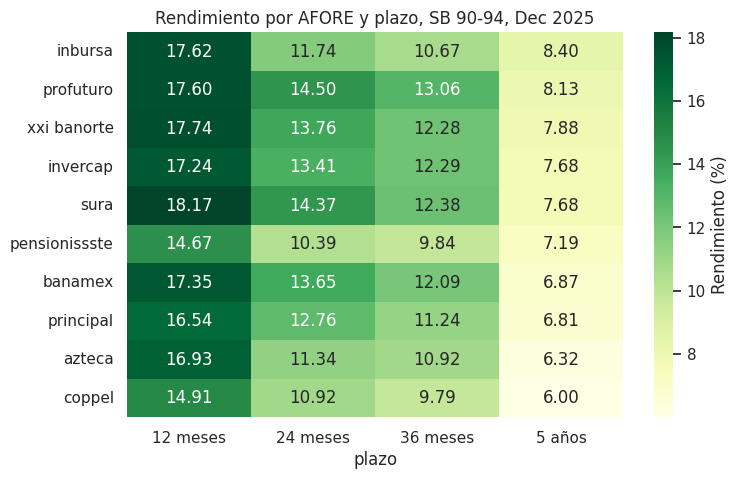

plazo,12 meses,24 meses,36 meses,5 años
afore,,,,
inbursa,17.6204,11.7418,10.6685,8.3963
profuturo,17.6005,14.5040,13.0611,8.1293
xxi banorte,17.7378,13.7555,12.2802,7.8789
invercap,17.2392,13.4112,12.2905,7.6773
sura,18.1690,14.3745,12.3830,7.6764
pensionissste,14.6670,10.3882,9.8408,7.1921
banamex,17.3486,13.6524,12.0949,6.8682
principal,16.5365,12.7552,11.2397,6.8136
azteca,16.9284,11.3367,10.9220,6.3223


In [2]:
ultima = gen["fecha"].max()
rank = (gen[(gen.fondo == GEN) & (gen.fecha == ultima)]
        .pivot_table(index="afore", columns="plazo", values="monto")[PLAZOS]
        .sort_values("5 años", ascending=False))

plt.figure(figsize=(8, 5))
sns.heatmap(rank, annot=True, fmt=".2f", cmap="YlGn", cbar_kws={"label": "Rendimiento (%)"})
plt.title(f"Rendimiento por AFORE y plazo, SB {GEN}, {ultima:%b %Y}")
plt.ylabel("")
plt.savefig("../images/01/01_heatmap_rendimientos.png", dpi=150, bbox_inches="tight")
plt.show()
rank

## 2. ¿Es consistente el ranking?
Correlación de Spearman entre el orden de las AFOREs a 12 meses y a 5 años, mes por mes. Cerca de 1 significa que la que gana en el corto también gana en el largo, y cerca de 0 o negativo que el corto plazo no dice nada.

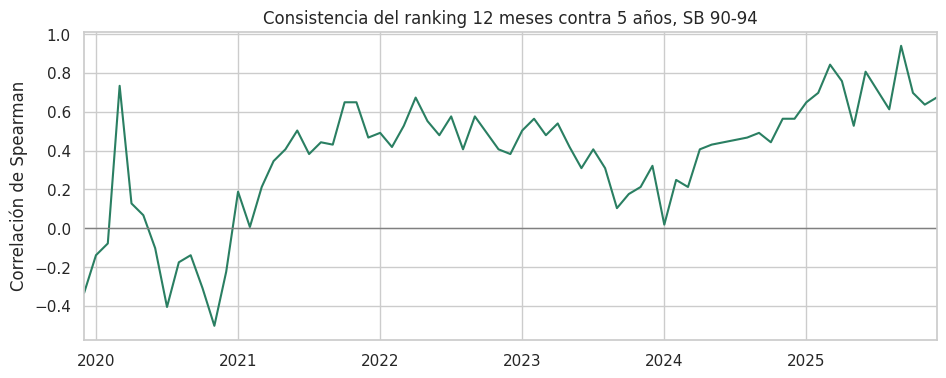

promedio: 0.37 | mediana: 0.44 | meses con correlación negativa: 14%


,corr_promedio
55-59,0.40
60-64,0.32
65-69,0.32
70-74,0.42
75-79,0.44
80-84,0.42
85-89,0.39
90-94,0.37
95-99,0.65


In [3]:
def consistencia(fondo):
    p = (gen[gen.fondo == fondo]
         .pivot_table(index=["fecha", "afore"], columns="plazo", values="monto")[PLAZOS]
         .reset_index())
    return pd.Series({f: spearmanr(g["12 meses"], g["5 años"])[0] for f, g in p.groupby("fecha")})

cons = consistencia(GEN)

fig, ax = plt.subplots(figsize=(11, 4))
cons.plot(ax=ax, color="#2a7f62")
ax.axhline(0, color="gray", lw=1)
ax.set_title(f"Consistencia del ranking 12 meses contra 5 años, SB {GEN}")
ax.set_ylabel("Correlación de Spearman")
plt.savefig("../images/01/02_consistencia_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"promedio: {cons.mean():.2f} | mediana: {cons.median():.2f} | meses con correlación negativa: {(cons < 0).mean():.0%}")

# lo mismo para todas las generaciones
resumen = pd.DataFrame({f: {"corr_promedio": consistencia(f).mean()} for f in sorted(gen.fondo.unique())}).T
resumen.round(2)

## 3. La caída de 2022

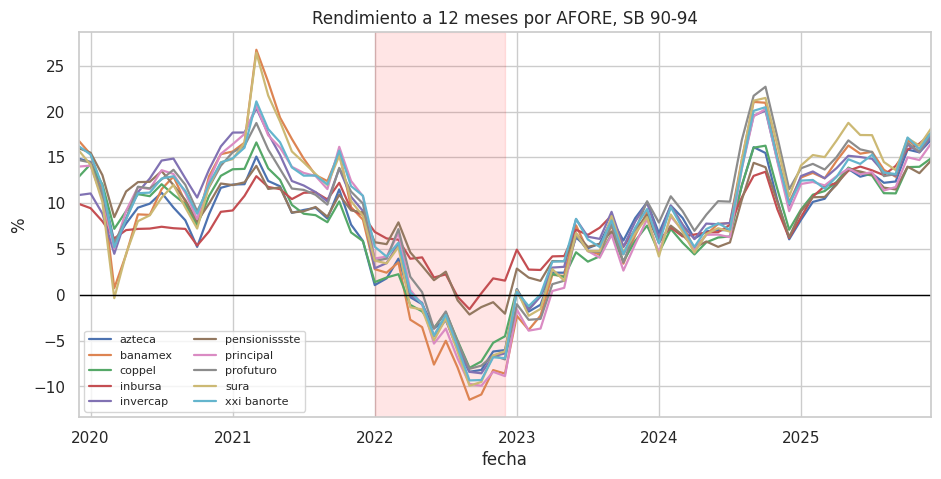

,peor_12m,mes_del_peor,meses_negativos_%,desv_estandar
afore,,,,
inbursa,-1.57,2022-09,2.74,4.01
pensionissste,-2.15,2022-09,6.85,4.54
coppel,-7.97,2022-09,15.07,6.08
profuturo,-8.07,2022-09,13.70,7.21
azteca,-8.39,2022-09,15.07,6.14
invercap,-8.56,2022-10,15.07,7.08
xxi banorte,-9.34,2022-09,12.33,7.17
sura,-9.92,2022-09,16.44,8.02
principal,-9.92,2022-10,15.07,7.56


In [4]:
s = (gen[(gen.fondo == GEN) & (gen.plazo == "12 meses")]
     .pivot(index="fecha", columns="afore", values="monto"))

fig, ax = plt.subplots(figsize=(11, 5))
s.plot(ax=ax, lw=1.6)
ax.axhline(0, color="black", lw=1)
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), alpha=0.1, color="red")
ax.set_title(f"Rendimiento a 12 meses por AFORE, SB {GEN}")
ax.set_ylabel("%")
ax.legend(ncol=2, fontsize=8)
plt.savefig("../images/01/03_crisis_2022.png", dpi=150, bbox_inches="tight")
plt.show()

estabilidad = pd.DataFrame({
    "peor_12m": s.min(),
    "mes_del_peor": s.idxmin().dt.strftime("%Y-%m"),
    "meses_negativos_%": (s < 0).mean() * 100,
    "desv_estandar": s.std(),
}).sort_values("peor_12m", ascending=False)
estabilidad.round(2)

## 4. Rendimiento contra estabilidad

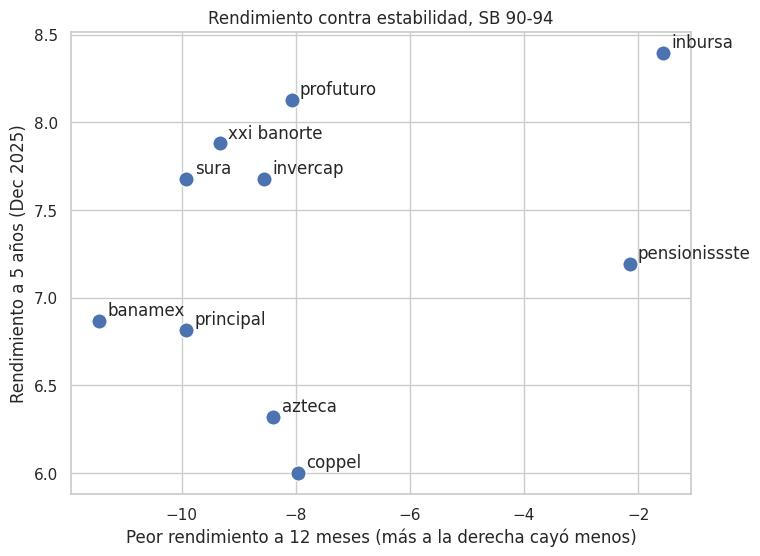

,peor_12m,mes_del_peor,meses_negativos_%,desv_estandar,rend_5a_actual
afore,,,,,
inbursa,-1.57,2022-09,2.74,4.01,8.40
pensionissste,-2.15,2022-09,6.85,4.54,7.19
coppel,-7.97,2022-09,15.07,6.08,6.00
profuturo,-8.07,2022-09,13.70,7.21,8.13
azteca,-8.39,2022-09,15.07,6.14,6.32
invercap,-8.56,2022-10,15.07,7.08,7.68
xxi banorte,-9.34,2022-09,12.33,7.17,7.88
sura,-9.92,2022-09,16.44,8.02,7.68
principal,-9.92,2022-10,15.07,7.56,6.81


In [5]:
perfil = estabilidad.join(rank["5 años"].rename("rend_5a_actual"))

plt.figure(figsize=(8, 6))
sns.scatterplot(data=perfil, x="peor_12m", y="rend_5a_actual", s=120)
for nombre, r in perfil.iterrows():
    plt.annotate(nombre, (r["peor_12m"], r["rend_5a_actual"]), xytext=(6, 4), textcoords="offset points")
plt.xlabel("Peor rendimiento a 12 meses (más a la derecha cayó menos)")
plt.ylabel(f"Rendimiento a 5 años ({ultima:%b %Y})")
plt.title(f"Rendimiento contra estabilidad, SB {GEN}")
plt.savefig("../images/01/04_perfil_rend_estabilidad.png", dpi=150, bbox_inches="tight")
plt.show()
perfil.round(2)

## Qué encontré (SB 90-94, dic 2025)

A 5 años la diferencia entre la mejor y la peor AFORE es de 2.4 puntos porcentuales: Inbursa 8.40% contra Coppel 6.00%. Los plazos largos vienen anualizados (lo compruebo en el notebook 03), así que esos 2.4 puntos son por año.

El ranking de corto plazo dice poco del largo plazo. La correlación de Spearman entre el ranking a 12 meses y el de 5 años promedia 0.37 (mediana 0.44) y es negativa en 14% de los meses. Sura, por ejemplo, es la primera a 12 meses (18.17%) pero queda a media tabla a 5 años (7.68%).

2022 fue el golpe. Para casi todas las AFOREs el peor rendimiento a 12 meses ocurrió en septiembre u octubre de 2022, y la caída fue muy distinta entre ellas: Inbursa -1.57% y PensionISSSTE -2.15%, contra Sura y Principal -9.92% y Banamex -11.45%.

En la foto de dic 2025 Inbursa tiene el mejor rendimiento a 5 años con una de las menores caídas. Pero una foto de un solo mes engaña: mirando los 73 meses, la que más veces fue primera a 5 años es Profuturo (33 meses), y Inbursa es muy irregular a 12 meses (notebook 00). Es una sola generación y una sola ventana, así que no lo tomo como recomendación ni como predicción.

Sigue pendiente ver si el `monto` ya descuenta comisiones (notebook 02) y si estos patrones se repiten en las otras generaciones, para lo cual basta cambiar `GEN`.